# Crop Yield Prediction — Exploratory Data Analysis

## 1. Introduction

Crop yield prediction is an important machine learning problem in agriculture.  
It helps estimate the production of crops using historical and environmental factors such as rainfall, temperature, pesticide usage, crop type, country, and year.

In this notebook, we perform **Exploratory Data Analysis (EDA)** to understand the dataset before applying data cleaning and machine learning models.

### Dataset Description

The dataset contains agricultural production records from multiple countries and crop types.  
Each row represents the yield information for a particular crop in a specific country and year.

### Main Objective

The main objective of this project is to predict:

**`hg/ha_yield`** — crop yield measured in hectograms per hectare.

### EDA Goals

In this notebook, we will:

- Load and inspect the dataset
- Understand the structure of the data
- Check missing values and duplicates
- Analyze numerical and categorical features
- Study crop yield distribution
- Explore relationships between yield and environmental factors
- Identify patterns useful for model building

## 1. Imports and Load Data

In this section, we import the required Python libraries and load the crop yield dataset.

We also import the custom `load_data()` function from the `utils.py` file. This function helps load the CSV file and automatically removes unnecessary unnamed index columns if they exist.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sys
import os

# Ignore warning messages for cleaner notebook output
warnings.filterwarnings("ignore")

# Add src folder path to access utils.py
sys.path.insert(0, os.path.abspath("../src"))

# Import custom data loading function
from utils import load_data

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display all columns in pandas output
pd.set_option("display.max_columns", None)

# Load dataset
df = load_data("../data/yield_df.csv")

# Display dataset size
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Show first 5 records
df.head()

Dataset loaded successfully!
Number of rows: 28242
Number of columns: 7


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


## 2. Dataset Overview

Before performing detailed analysis, we first check the basic structure of the dataset.

This includes:

- Dataset shape
- Column data types
- Summary statistics for numerical and categorical columns

This helps us understand the size of the dataset and the type of features available for analysis.

In [2]:
# Display basic dataset information

print("Dataset Shape")
print("-" * 40)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData Types")
print("-" * 40)
display(df.dtypes.to_frame(name="Data Type"))

print("\nStatistical Summary")
print("-" * 40)
display(df.describe(include="all").round(2))

Dataset Shape
----------------------------------------
Rows: 28242
Columns: 7

Data Types
----------------------------------------


,Data Type
Area,str
Item,str
Year,int64
hg/ha_yield,int64
average_rain_fall_mm_per_year,float64
pesticides_tonnes,float64
avg_temp,float64



Statistical Summary
----------------------------------------


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242,28242,28242.00,28242.00,28242.00,28242.00,28242.00
unique,101,10,NaN,NaN,NaN,NaN,NaN
top,India,Potatoes,NaN,NaN,NaN,NaN,NaN
freq,4048,4276,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2001.54,77053.33,1149.06,37076.91,20.54
std,NaN,NaN,7.05,84956.61,709.81,59958.78,6.31
min,NaN,NaN,1990.00,50.00,51.00,0.04,1.30
25%,NaN,NaN,1995.00,19919.25,593.00,1702.00,16.70
50%,NaN,NaN,2001.00,38295.00,1083.00,17529.44,21.51
75%,NaN,NaN,2008.00,104676.75,1668.00,48687.88,26.00


In [3]:
# Check duplicate records

duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate Records")
print("-" * 40)
print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

# Check missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

print("\nMissing Values")
print("-" * 40)
display(missing_values)

# Check unique values and year range
print("\nDataset Coverage")
print("-" * 40)
print("Number of countries/areas:", df["Area"].nunique())
print("Number of crop types:", df["Item"].nunique())
print("Year range:", df["Year"].min(), "to", df["Year"].max())

Duplicate Records
----------------------------------------
Number of duplicate rows: 2310
Duplicate percentage: 8.18 %

Missing Values
----------------------------------------


,Missing Values,Percentage
Area,0,0.0
Item,0,0.0
Year,0,0.0
hg/ha_yield,0,0.0
average_rain_fall_mm_per_year,0,0.0
pesticides_tonnes,0,0.0
avg_temp,0,0.0



Dataset Coverage
----------------------------------------
Number of countries/areas: 101
Number of crop types: 10
Year range: 1990 to 2013


### Observations

From the initial dataset overview:

- The dataset contains **28,242 rows** and **7 columns**.
- There are **101 countries/areas** and **10 crop types**.
- The records cover the period from **1990 to 2013**.
- There are **no missing values** in the dataset.
- There are **2,310 duplicate rows**, which should be removed during the data cleaning stage.

Since duplicate rows are present, they will be handled in the next notebook before model building.

## 4. Target Variable Distribution

The target variable of this project is **`hg/ha_yield`**, which represents crop yield measured in hectograms per hectare.

Since this is a **regression problem**, understanding the target variable is very important before building machine learning models.

In this section, we analyze:

- The distribution of crop yield values
- Whether the target variable is skewed
- Whether extreme values or outliers are present
- The mean and median yield values

This helps us understand how crop yield values are spread across the dataset.

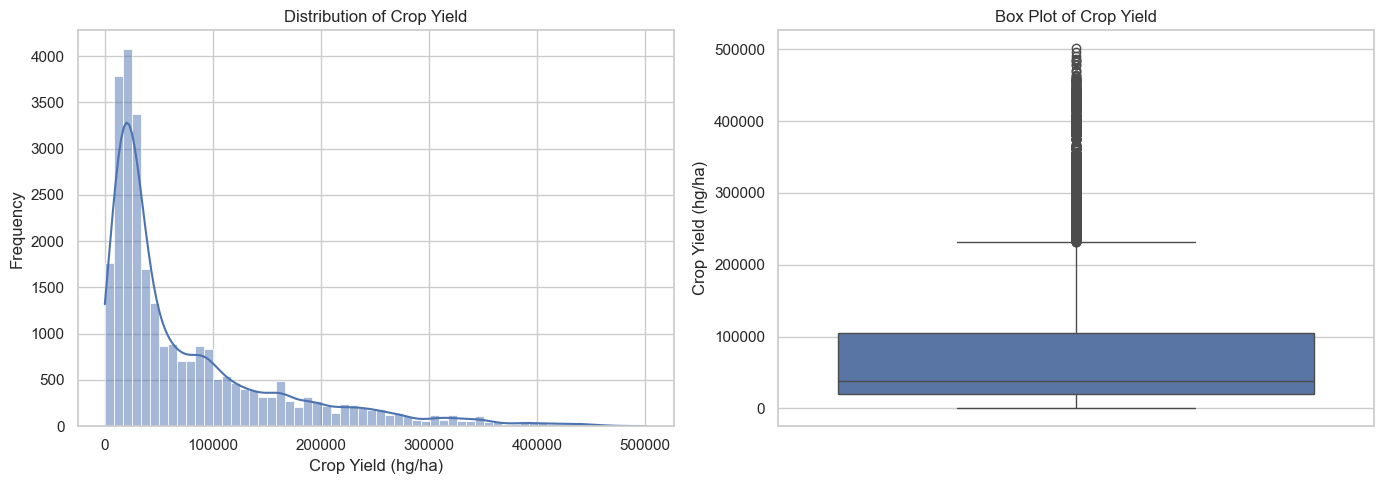

{'Mean Yield': np.float64(77053.33),
 'Median Yield': np.float64(38295.0),
 'Minimum Yield': np.int64(50),
 'Maximum Yield': np.int64(501412),
 'Skewness': np.float64(1.793)}

In [4]:
# Analyze target variable distribution

target_col = "hg/ha_yield"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=df,
    x=target_col,
    bins=60,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Crop Yield")
axes[0].set_xlabel("Crop Yield (hg/ha)")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    data=df,
    y=target_col,
    ax=axes[1]
)

axes[1].set_title("Box Plot of Crop Yield")
axes[1].set_ylabel("Crop Yield (hg/ha)")

plt.tight_layout()
plt.show()

# Summary statistics for target variable
target_summary = {
    "Mean Yield": round(df[target_col].mean(), 2),
    "Median Yield": round(df[target_col].median(), 2),
    "Minimum Yield": round(df[target_col].min(), 2),
    "Maximum Yield": round(df[target_col].max(), 2),
    "Skewness": round(df[target_col].skew(), 3)
}

target_summary

### Observations

From the target variable analysis:

- The crop yield values are **not normally distributed**.
- The distribution is **right-skewed**, meaning most crop yield values are concentrated at lower ranges.
- The mean yield is higher than the median yield, which confirms the presence of high-value extreme observations.
- The box plot shows several outliers in the target variable.
- These outliers may be valid agricultural records, so they should not be removed immediately without further analysis.

This is important because skewness and outliers can affect the performance of regression models.

## 5. Univariate Analysis of Numerical Features

In this section, we analyze the distribution of the numerical predictor variables.

The numerical features are:

- `average_rain_fall_mm_per_year`
- `pesticides_tonnes`
- `avg_temp`
- `Year`

For each feature, we use:

- **Histogram** to understand the distribution
- **Box plot** to identify spread and possible outliers

This analysis helps us understand whether numerical features are normally distributed, skewed, or affected by extreme values.

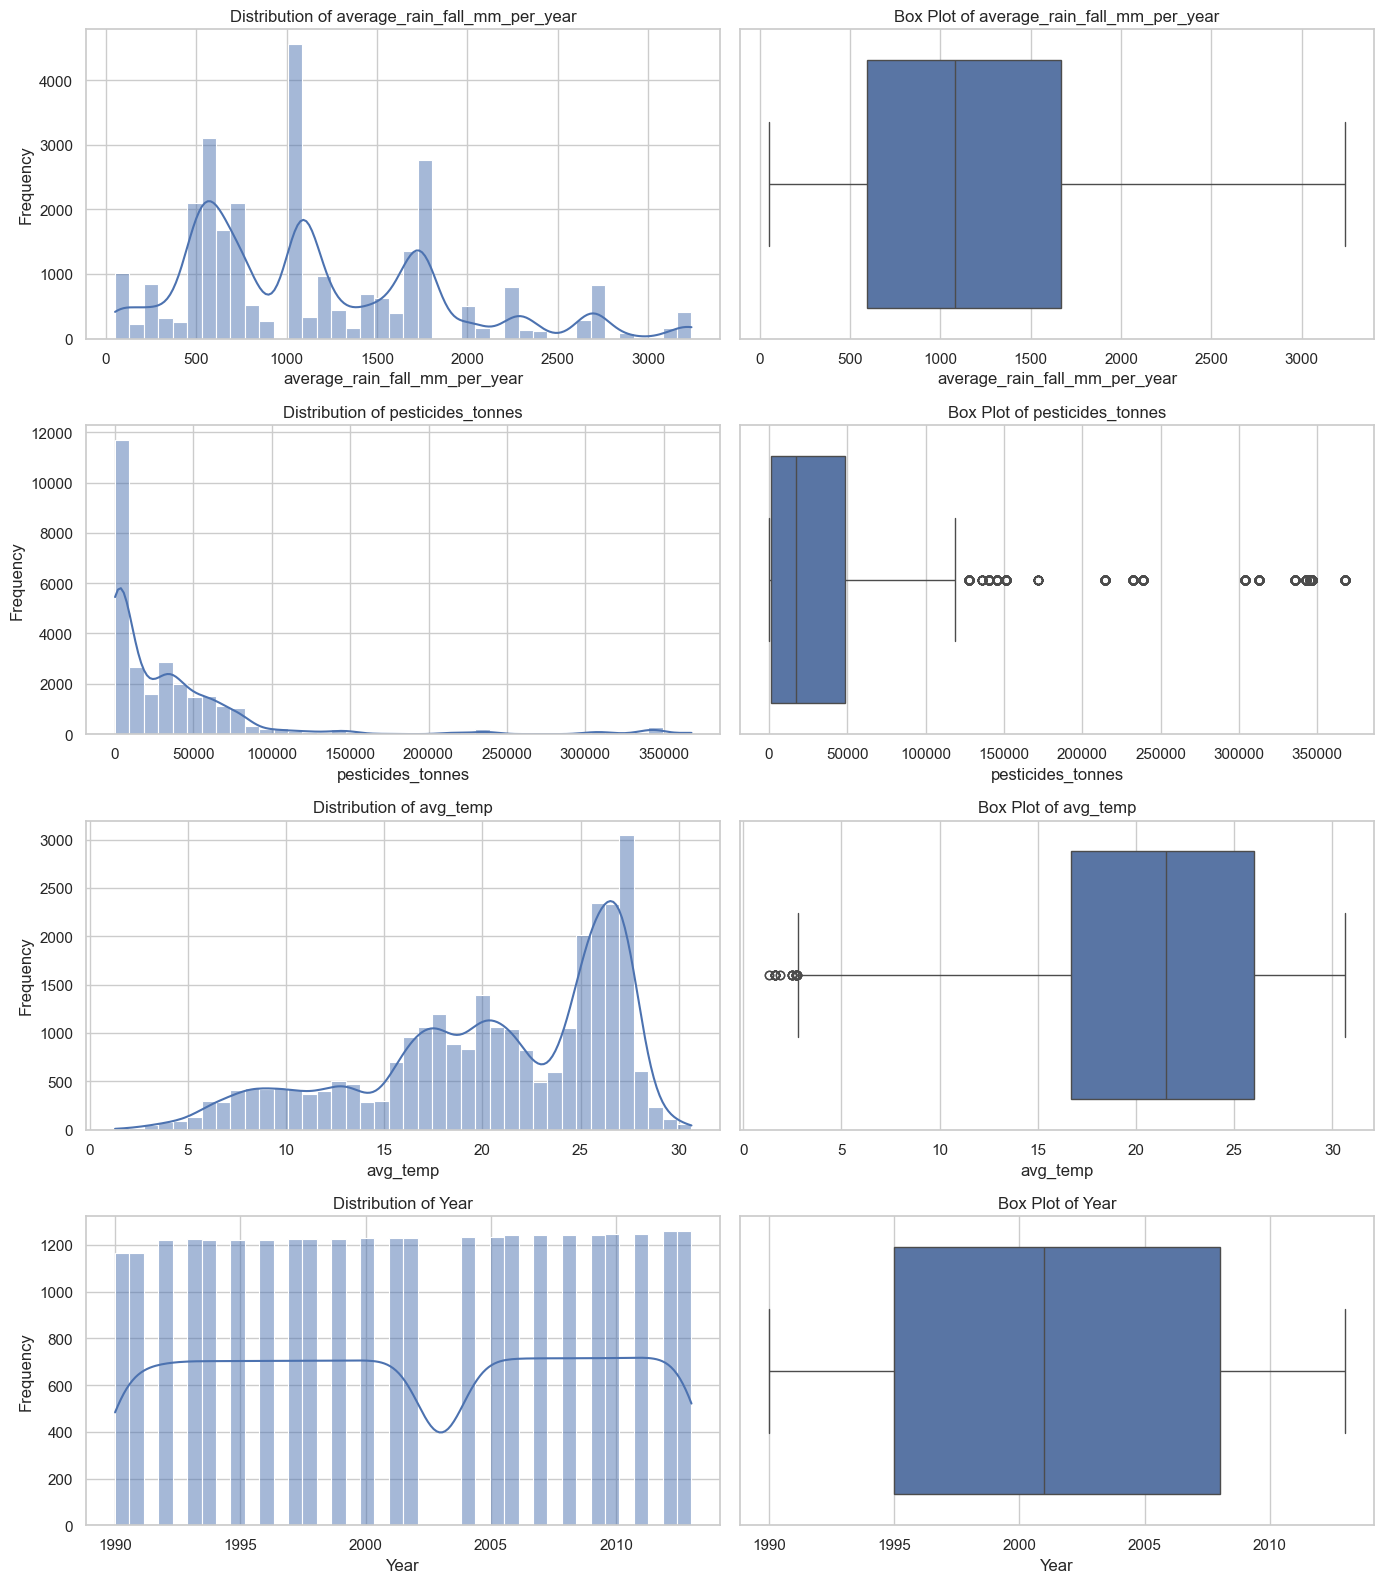

In [5]:
# Univariate analysis of numerical features

num_features = [
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "Year"
]

fig, axes = plt.subplots(len(num_features), 2, figsize=(14, 16))

for i, col in enumerate(num_features):
    
    # Histogram
    sns.histplot(
        data=df,
        x=col,
        bins=40,
        kde=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Distribution of {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frequency")
    
    # Box plot
    sns.boxplot(
        data=df,
        x=col,
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"Box Plot of {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

### Observations

From the numerical feature analysis:

- `average_rain_fall_mm_per_year` shows variation across countries and years.
- `pesticides_tonnes` is highly right-skewed and contains several extreme values.
- `avg_temp` is distributed across a reasonable temperature range, but some low-temperature outliers are visible.
- `Year` is fairly evenly distributed from 1990 to 2013.
- Outliers are mainly visible in pesticide usage and crop yield-related features.

These patterns are important because skewed features and outliers may affect machine learning model performance.

## 6. Bivariate Analysis

Bivariate analysis helps us understand the relationship between two variables.

In this section, we analyze:

- How numerical features relate to crop yield
- How crop yield differs across crop types
- Which crop types have the highest average yield
- Which countries have the highest average yield

This helps identify important patterns that may influence the machine learning model.

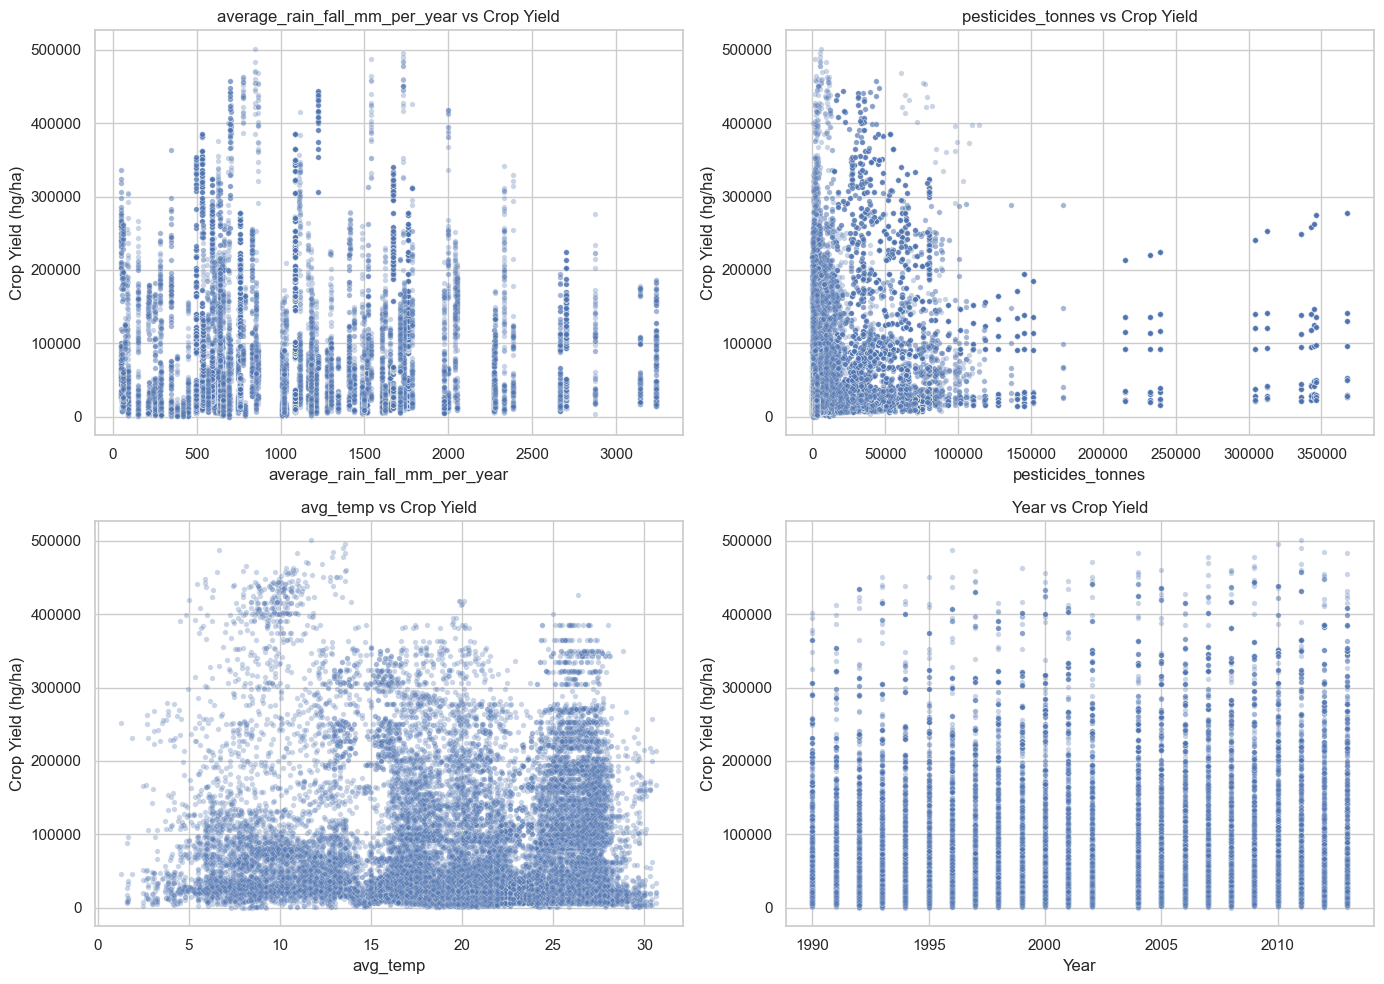

In [6]:
# Relationship between numerical features and crop yield

target_col = "hg/ha_yield"

num_features = [
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "Year"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.scatterplot(
        data=df,
        x=col,
        y=target_col,
        alpha=0.3,
        s=15,
        ax=axes[i]
    )
    
    axes[i].set_title(f"{col} vs Crop Yield")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Crop Yield (hg/ha)")

plt.tight_layout()
plt.show()

#### Observations

From the scatter plots:

- Rainfall shows variation across different yield levels, but the relationship is not strongly linear.
- Pesticide usage contains many extreme values and does not show a simple direct relationship with crop yield.
- Average temperature shows a wide spread of yield values across different temperature ranges.
- Crop yield changes across years, but year alone may not be enough to explain yield variation.

Overall, the relationship between crop yield and the numerical features appears complex, so machine learning models may be useful for capturing hidden patterns.

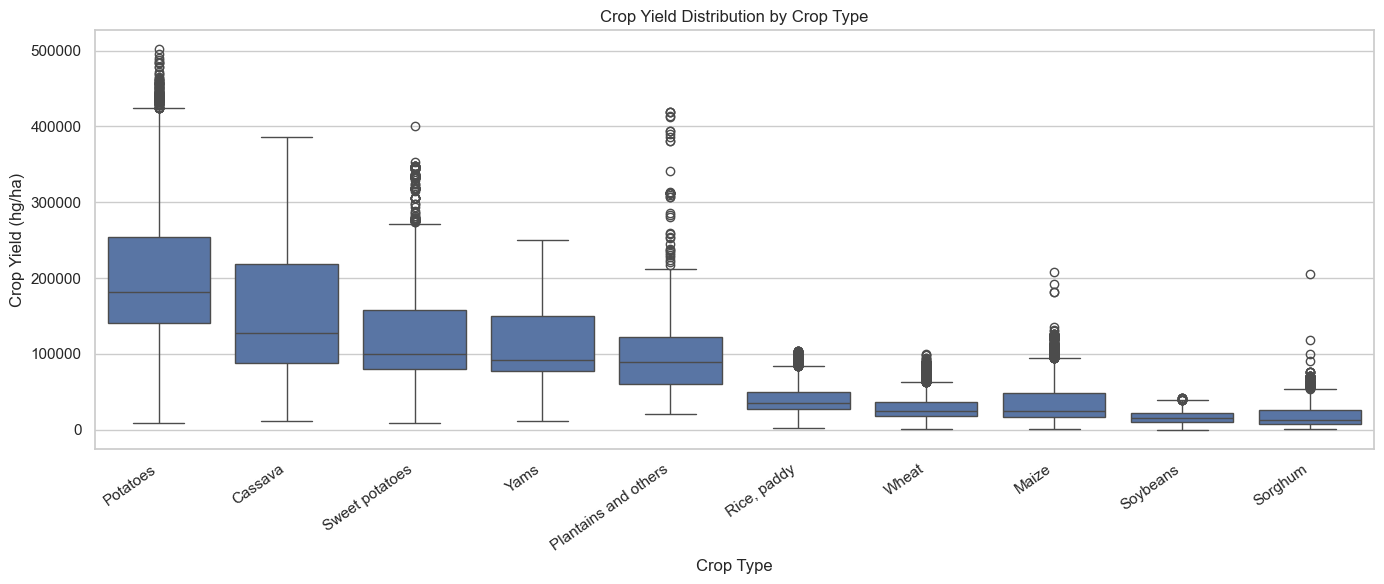

In [7]:
# Yield distribution by crop type

plt.figure(figsize=(14, 6))

crop_order = (
    df.groupby("Item")[target_col]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df,
    x="Item",
    y=target_col,
    order=crop_order
)

plt.title("Crop Yield Distribution by Crop Type")
plt.xlabel("Crop Type")
plt.ylabel("Crop Yield (hg/ha)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

#### Observations

From the crop type box plot:

- Potatoes have the highest median crop yield.
- Cassava, sweet potatoes, yams, and plantains also show relatively high yield values.
- Soybeans, sorghum, wheat, and maize show lower yield distributions compared to root crops.
- Several crop types contain outliers, which may represent unusually high-yield records.

This shows that crop type is likely to be an important predictor for crop yield.

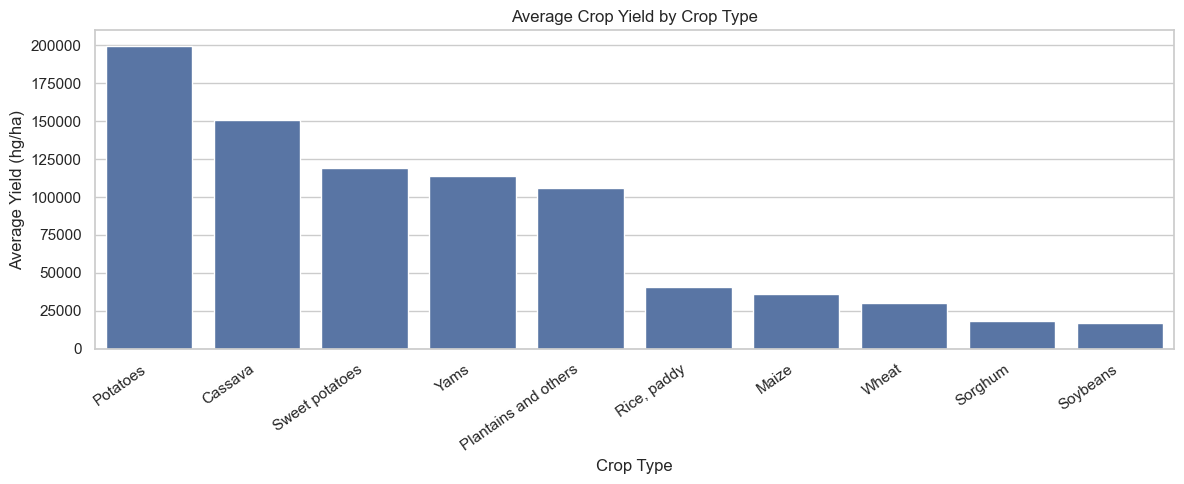

Item
Potatoes                199801.55
Cassava                 150479.47
Sweet potatoes          119057.79
Yams                    114140.35
Plantains and others    106041.32
Rice, paddy              40730.43
Maize                    36310.07
Wheat                    30116.27
Sorghum                  18635.78
Soybeans                 16731.09
Name: hg/ha_yield, dtype: float64

In [8]:
# Mean yield by crop type

mean_by_crop = (
    df.groupby("Item")[target_col]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=mean_by_crop.index,
    y=mean_by_crop.values
)

plt.title("Average Crop Yield by Crop Type")
plt.xlabel("Crop Type")
plt.ylabel("Average Yield (hg/ha)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Display values
mean_by_crop.round(2)

#### Observations

From the average crop yield ranking:

- Potatoes have the highest average yield.
- Cassava, sweet potatoes, yams, and plantains also have high average yields.
- Soybeans and sorghum have the lowest average yields among the listed crop types.
- The difference between crop types is large, which confirms that crop type has a strong influence on yield.

This feature should be encoded properly before model building.

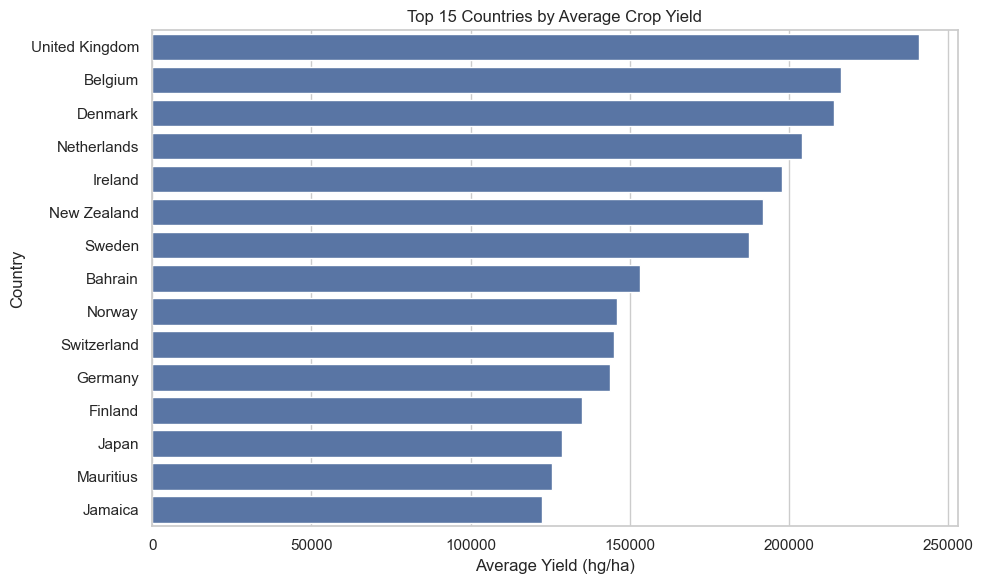

Area
United Kingdom    240956.48
Belgium           216468.46
Denmark           214033.02
Netherlands       204151.20
Ireland           197913.70
New Zealand       191931.83
Sweden            187405.50
Bahrain           153237.55
Norway            146115.33
Switzerland       144960.28
Germany           143631.34
Finland           135014.52
Japan             128851.88
Mauritius         125586.26
Jamaica           122347.87
Name: hg/ha_yield, dtype: float64

In [9]:
# Top 15 countries by average crop yield

top_countries = (
    df.groupby("Area")[target_col]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 15 Countries by Average Crop Yield")
plt.xlabel("Average Yield (hg/ha)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# Display values
top_countries.round(2)

#### Observations

From the top country analysis:

- The United Kingdom shows the highest average crop yield in this dataset.
- Belgium, Denmark, Netherlands, and Ireland also appear among the top-yielding countries.
- Many high-yielding countries are from Europe.
- Country or area appears to be an important factor because agricultural productivity differs by region.

This suggests that the `Area` feature may provide useful information for predicting crop yield.

## 7. Correlation Analysis

Correlation analysis helps us understand the linear relationship between numerical variables.

In this section, we calculate the correlation between numerical features and the target variable `hg/ha_yield`.

Since `Area` and `Item` are categorical columns, they are not included in this correlation heatmap. Their effect was analyzed separately using crop-wise and country-wise visualizations.

A correlation value can range from:

- **+1**: strong positive relationship
- **0**: no linear relationship
- **-1**: strong negative relationship## 6. Correlation Analysis

A heatmap of the numeric features (including the target) reveals linear relationships. Because
`Area` and `Item` are categorical, they are excluded here — their impact appears in the bivariate
section above.

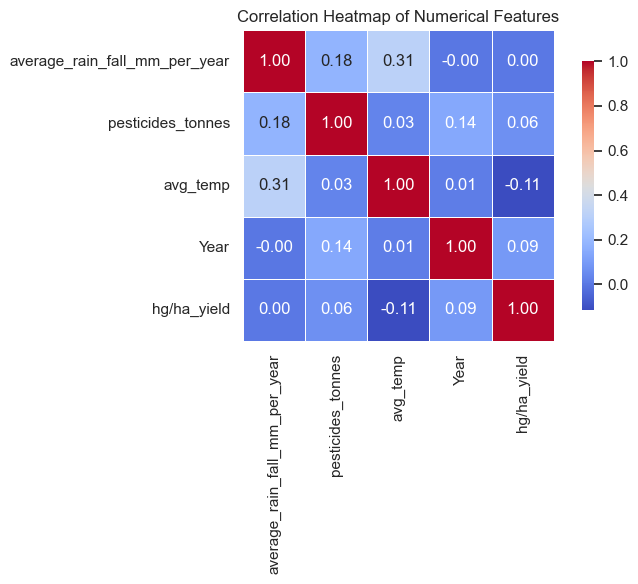

Year                             0.091630
pesticides_tonnes                0.064085
average_rain_fall_mm_per_year    0.000962
avg_temp                        -0.114777
Name: hg/ha_yield, dtype: float64

In [10]:
# Correlation analysis for numerical features

numeric_columns = [
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "Year",
    "hg/ha_yield"
]

# Create correlation matrix
correlation_matrix = df[numeric_columns].corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Display correlation values with target variable
target_correlations = (
    correlation_matrix["hg/ha_yield"]
    .drop("hg/ha_yield")
    .sort_values(ascending=False)
)

target_correlations

### Observations

From the correlation analysis:

- `Year` has a weak positive correlation with crop yield.
- `pesticides_tonnes` also shows a weak positive correlation with crop yield.
- `average_rain_fall_mm_per_year` has almost no linear correlation with crop yield.
- `avg_temp` shows a weak negative correlation with crop yield.
- None of the numerical features show a strong linear relationship with the target variable.

This suggests that crop yield prediction may depend more on a combination of features rather than one strong individual numerical feature.

Also, categorical features such as `Area` and `Item` may play an important role and should be encoded before model building.

## 8. Domain Deep-Dive

In this section, we explore agriculture-specific questions to understand the dataset more deeply.

We analyze:

- Global crop yield trend over time
- Yield trend by crop type
- Best-performing country for each crop
- Pesticide usage trend over time

This helps connect the data analysis with real-world agricultural patterns.

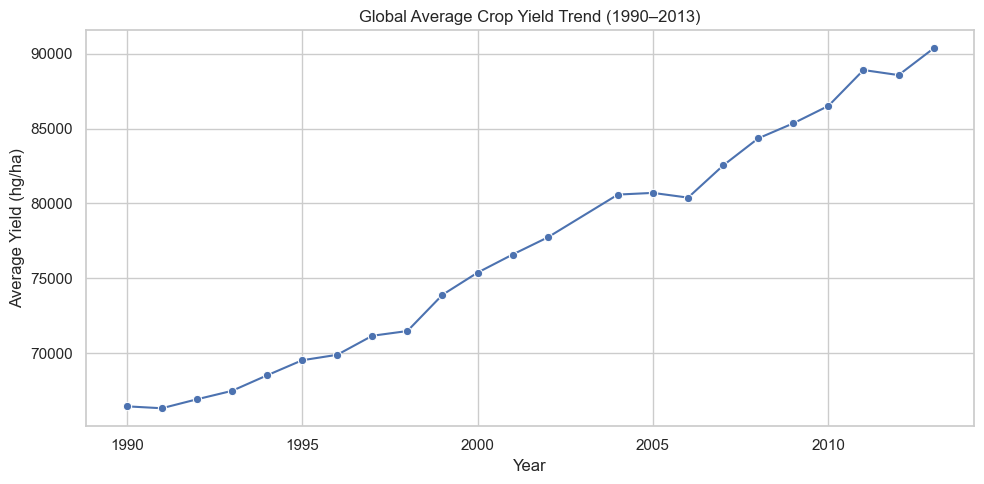

,Year,hg/ha_yield
18,2009,85350.016908
19,2010,86512.526104
20,2011,88908.335743
21,2012,88569.850794
22,2013,90357.363781


In [11]:
# Global mean crop yield trend over years

yearly_yield = (
    df.groupby("Year")["hg/ha_yield"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_yield,
    x="Year",
    y="hg/ha_yield",
    marker="o"
)

plt.title("Global Average Crop Yield Trend (1990–2013)")
plt.xlabel("Year")
plt.ylabel("Average Yield (hg/ha)")
plt.tight_layout()
plt.show()

yearly_yield.tail()

#### Observations

From the global crop yield trend:

- The average crop yield shows an overall increasing trend from 1990 to 2013.
- Crop yield increased gradually during the 1990s.
- A stronger upward trend can be seen after the early 2000s.
- This indicates that crop productivity improved over time in the dataset.

This pattern may be influenced by improvements in farming methods, technology, crop varieties, and agricultural practices.

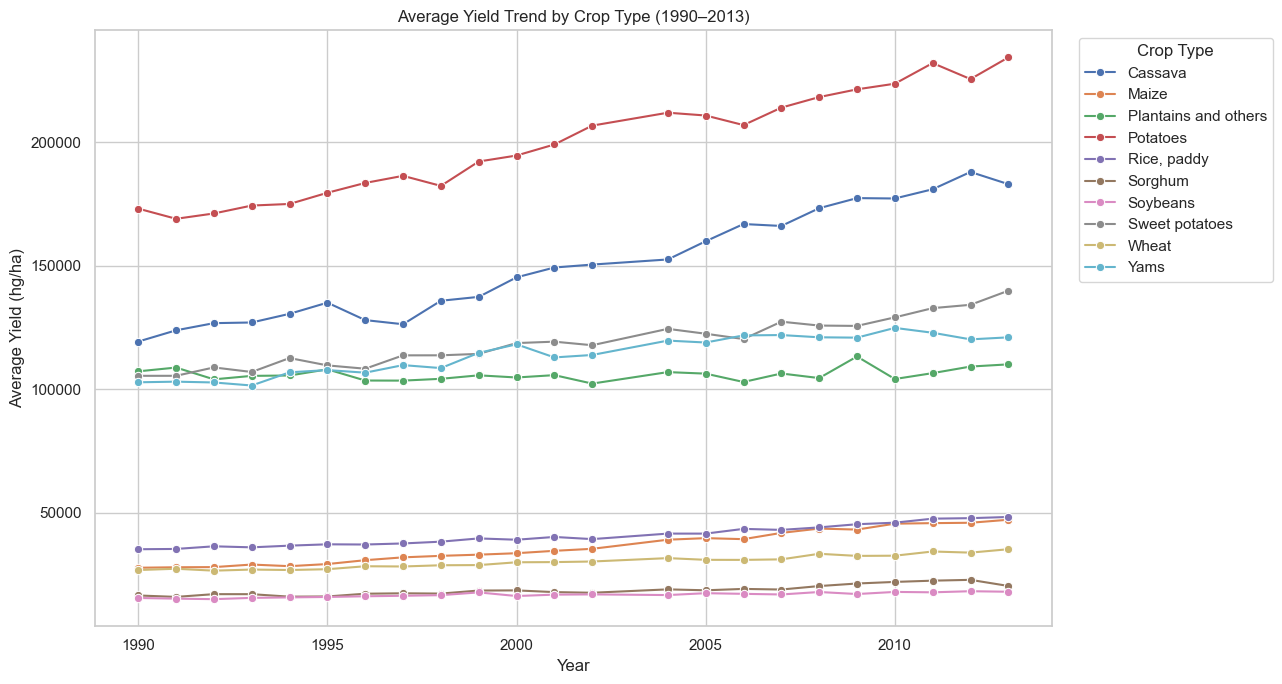

In [12]:
# Mean yield trend by crop type

crop_yearly_yield = (
    df.groupby(["Year", "Item"])["hg/ha_yield"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=crop_yearly_yield,
    x="Year",
    y="hg/ha_yield",
    hue="Item",
    marker="o"
)

plt.title("Average Yield Trend by Crop Type (1990–2013)")
plt.xlabel("Year")
plt.ylabel("Average Yield (hg/ha)")
plt.legend(title="Crop Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Observations

From the crop-wise yield trend:

- Potatoes consistently show the highest average yield across the years.
- Cassava also shows a strong increasing trend over time.
- Sweet potatoes, yams, and plantains maintain relatively high yield values.
- Crops such as soybeans, sorghum, wheat, maize, and rice show lower average yields.
- Most crop types show some level of improvement over time.

This confirms that crop type strongly affects yield and should be included as an important feature in model building.

In [13]:
# Top-performing country for each crop type

top_country_per_crop = (
    df.groupby(["Item", "Area"])["hg/ha_yield"]
    .mean()
    .reset_index()
)

top_country_per_crop = top_country_per_crop.loc[
    top_country_per_crop.groupby("Item")["hg/ha_yield"].idxmax()
]

top_country_per_crop = (
    top_country_per_crop
    .sort_values("hg/ha_yield", ascending=False)
    .reset_index(drop=True)
)

top_country_per_crop["hg/ha_yield"] = top_country_per_crop["hg/ha_yield"].round(2)

top_country_per_crop

,Item,Area,hg/ha_yield
0,Potatoes,Belgium,448891.54
1,Plantains and others,Guatemala,291096.30
2,Cassava,India,282234.43
3,Sweet potatoes,Egypt,261369.35
4,Yams,Japan,211343.43
5,Maize,Qatar,136593.00
6,"Rice, paddy",Egypt,89234.70
7,Wheat,Belgium,84988.62
8,Sorghum,Austria,63873.25
9,Soybeans,Italy,34446.70


#### Observations

From the best-performing country per crop analysis:

- Belgium has the highest average yield for potatoes.
- Guatemala leads in plantains and others.
- India shows the highest average yield for cassava.
- Egypt performs strongly for sweet potatoes and rice.
- Different countries lead in different crop types, showing that crop productivity depends on both crop type and region.

This supports the importance of using both `Area` and `Item` as input features for prediction.

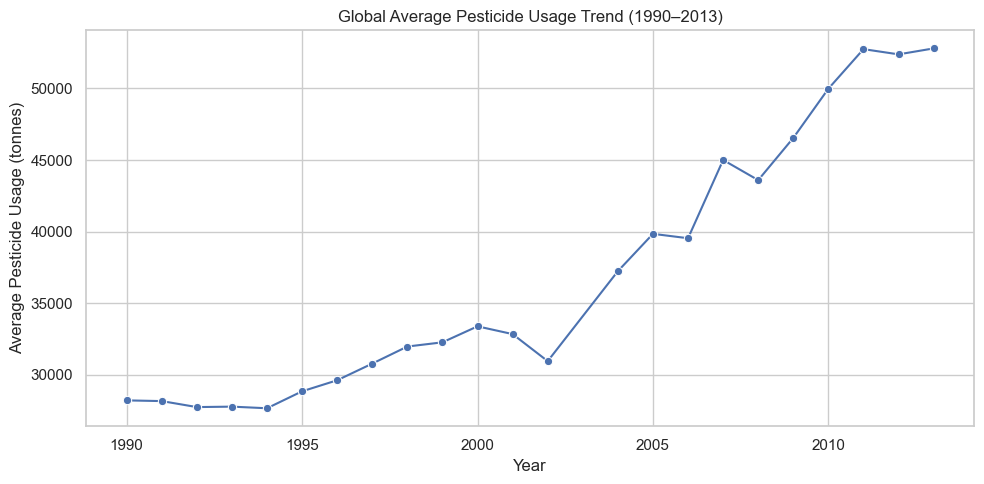

,Year,pesticides_tonnes
18,2009,46542.982319
19,2010,49978.531831
20,2011,52738.488779
21,2012,52374.453611
22,2013,52789.887164


In [14]:
# Global mean pesticide usage trend over years

yearly_pesticide = (
    df.groupby("Year")["pesticides_tonnes"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_pesticide,
    x="Year",
    y="pesticides_tonnes",
    marker="o"
)

plt.title("Global Average Pesticide Usage Trend (1990–2013)")
plt.xlabel("Year")
plt.ylabel("Average Pesticide Usage (tonnes)")
plt.tight_layout()
plt.show()

yearly_pesticide.tail()

#### Observations

From the pesticide usage trend:

- Average pesticide usage increased over the years.
- The increase becomes more noticeable after the early 2000s.
- This suggests that pesticide usage may have changed along with agricultural productivity.
- However, correlation analysis showed only a weak relationship between pesticide usage and crop yield.

Therefore, pesticide usage may contribute to prediction, but it is unlikely to explain crop yield alone.

## 9. Summary of Key Findings

This section summarizes the main findings from the Exploratory Data Analysis.

These findings will help guide the next steps in the project, especially data cleaning, preprocessing, feature encoding, and model building.

In [15]:
# Summary of key findings from EDA

target_col = "hg/ha_yield"

mean_by_crop = df.groupby("Item")[target_col].mean()
mean_by_country = df.groupby("Area")[target_col].mean()

summary = pd.DataFrame({
    "Finding": [
        "Dataset size",
        "Countries/Areas",
        "Crop types",
        "Year range",
        "Target variable",
        "Target skewness",
        "Missing values",
        "Duplicate rows",
        "Highest average yield crop",
        "Lowest average yield crop",
        "Top average yield country",
        "Yield trend",
        "Pesticide usage trend",
        "Strongest numeric correlation"
    ],
    "Detail": [
        f"{df.shape[0]:,} rows and {df.shape[1]} columns",
        f"{df['Area'].nunique()} countries/areas",
        f"{df['Item'].nunique()} crop types",
        f"{df['Year'].min()} to {df['Year'].max()}",
        "hg/ha_yield",
        f"{df[target_col].skew():.2f} - right-skewed distribution",
        f"{df.isnull().sum().sum()} missing values",
        f"{df.duplicated().sum()} duplicate rows",
        f"{mean_by_crop.idxmax()} ({mean_by_crop.max():,.0f} hg/ha)",
        f"{mean_by_crop.idxmin()} ({mean_by_crop.min():,.0f} hg/ha)",
        f"{mean_by_country.idxmax()} ({mean_by_country.max():,.0f} hg/ha)",
        "Average crop yield shows an increasing trend over time",
        "Average pesticide usage also increases over time",
        "Numerical features show weak linear correlation with crop yield"
    ]
})

summary

,Finding,Detail
0,Dataset size,"28,242 rows and 7 columns"
1,Countries/Areas,101 countries/areas
2,Crop types,10 crop types
3,Year range,1990 to 2013
4,Target variable,hg/ha_yield
5,Target skewness,1.79 - right-skewed distribution
6,Missing values,0 missing values
7,Duplicate rows,2310 duplicate rows
8,Highest average yield crop,"Potatoes (199,802 hg/ha)"
9,Lowest average yield crop,"Soybeans (16,731 hg/ha)"


### Final EDA Observations

The Exploratory Data Analysis shows that the dataset is suitable for a regression-based machine learning project.

Main conclusions:

- The dataset contains agricultural records from multiple countries, crops, and years.
- The target variable `hg/ha_yield` is right-skewed and contains outliers.
- There are no missing values in the dataset.
- There are duplicate rows, so duplicates should be removed during data cleaning.
- Crop type and country/area appear to be important features for predicting crop yield.
- Numerical features alone do not show strong linear correlation with crop yield.
- Average crop yield and pesticide usage both show increasing trends over time.

Based on these findings, the next notebook will focus on data cleaning and preprocessing.